# 01 · Quickstart: load the free sample and chart a company

Varve Fundamentals is US company financials taken straight from SEC filings: every
number carries the date it became public, and delisted companies are kept. This
notebook loads the free sample (25 companies, full quarterly and annual history) and
does the everyday things: look up a company, chart a series, compute a ratio.

The sample is downloaded from [varvedata.com](https://varvedata.com/data.html#samples)
on first run.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from varve_sample import load

pd.set_option("display.width", 200, "display.max_columns", 20)

q = load("fundamentals_quarterly")
a = load("fundamentals_annual")
companies = load("fundamentals_companies")
print(f"quarterly: {len(q):,} rows · annual: {len(a):,} rows · companies: {len(companies)}")

quarterly: 1,768 rows · annual: 523 rows · companies: 27


One row per company and fiscal period. `cik` is the SEC's permanent company id: join
on it, never on `ticker` (notebook 03 shows why). `filed` is the date the whole row
was public (notebook 02 is about using it).

In [2]:
q[["cik", "ticker", "period_end", "fiscal_year", "fiscal_period", "filed",
   "revenue", "net_income", "eps_diluted"]].tail()

,cik,ticker,period_end,fiscal_year,fiscal_period,filed,revenue,net_income,eps_diluted
1763,1744489,DIS,2025-06-30,2025.0,Q3,2025-08-06,2.365000e+10,5.262000e+09,2.920000
1764,1744489,DIS,2025-09-30,2025.0,Q4,2025-11-13,2.246400e+10,1.313000e+09,0.726619
1765,1744489,DIS,2025-12-31,2026.0,Q1,2026-02-02,2.598100e+10,2.402000e+09,1.340000
1766,1744489,DIS,2026-03-31,2026.0,Q2,2026-05-06,2.516800e+10,2.247000e+09,1.270000
1767,1744489,DIS,2026-06-30,2026.0,Q3,2026-08-05,2.524800e+10,2.638000e+09,1.510000


## Look up a company

Find the CIK by ticker in the companies table, then select by CIK.

In [3]:
companies[companies["ticker"] == "NVDA"][["cik", "ticker", "name", "former_names", "first_filed"]]

,cik,ticker,name,former_names,first_filed
17,1045810,NVDA,NVIDIA CORP,NVIDIA CORP/DE,2009-08-20


In [4]:
nvda = q[q["cik"] == 1045810].sort_values("period_end")
nvda[["period_end", "fiscal_period", "filed", "revenue", "gross_profit", "net_income"]].tail(8)

,period_end,fiscal_period,filed,revenue,gross_profit,net_income
1252,2024-10-31,Q3,2024-11-20,3.508200e+10,2.615600e+10,1.930900e+10
1253,2025-01-31,Q4,2025-02-26,3.933100e+10,2.872200e+10,2.209100e+10
1254,2025-04-30,Q1,2025-05-28,4.406200e+10,2.666800e+10,1.877500e+10
1255,2025-07-31,Q2,2025-08-27,4.674300e+10,3.385300e+10,2.642200e+10
1256,2025-10-31,Q3,2025-11-19,5.700600e+10,4.184900e+10,3.191000e+10
1257,2026-01-31,Q4,2026-02-25,6.812700e+10,5.109300e+10,4.296000e+10
1258,2026-04-30,Q1,2026-05-20,8.161500e+10,6.115700e+10,5.832100e+10
1259,2026-07-31,Q2,2026-08-26,9.622100e+10,7.214200e+10,5.968800e+10


## Chart quarterly revenue and gross margin

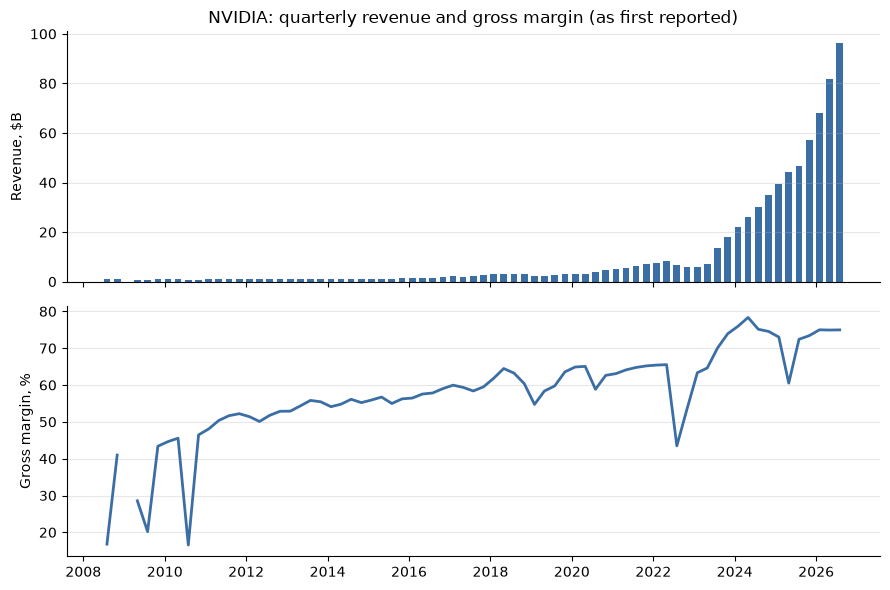

In [5]:
nvda = nvda.assign(gross_margin=nvda["gross_profit"] / nvda["revenue"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.bar(nvda["period_end"], nvda["revenue"] / 1e9, width=60, color="#3b6ea5")
ax1.set_ylabel("Revenue, $B")
ax1.set_title("NVIDIA: quarterly revenue and gross margin (as first reported)")
ax2.plot(nvda["period_end"], nvda["gross_margin"] * 100, color="#3b6ea5", lw=2)
ax2.set_ylabel("Gross margin, %")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Trailing-twelve-month figures

Flow items (revenue, income, cash flow) are per quarter, so TTM is a rolling sum of four
consecutive quarters. Check the four really are consecutive: a missing quarter would
otherwise silently stretch the window. Values are as filed, never filled in: operating
margin is blank for companies that report no operating-income line (Exxon, JPMorgan),
and free cash flow where there's no capex line (banks).

In [6]:
def ttm(df, col):
    df = df.sort_values("period_end")
    total = df.groupby("cik")[col].transform(lambda s: s.rolling(4).sum())
    span = df.groupby("cik")["period_end"].transform(lambda s: (s - s.shift(3)).dt.days)
    return total.where(span.between(250, 290))    # 4 quarters end ~273 days apart

q["revenue_ttm"] = ttm(q, "revenue")
q["operating_income_ttm"] = ttm(q, "operating_income")
q["fcf_ttm"] = ttm(q, "operating_cash_flow") - ttm(q, "capex")

latest = q.sort_values("period_end").groupby("cik").tail(1)
latest = latest[latest["period_end"] >= "2026-01-01"]
table = pd.DataFrame({
    "ticker": latest["ticker"],
    "period_end": latest["period_end"].dt.date,
    "revenue_ttm_B": latest["revenue_ttm"] / 1e9,
    "operating_margin_%": latest["operating_income_ttm"] / latest["revenue_ttm"] * 100,
    "fcf_ttm_B": latest["fcf_ttm"] / 1e9,
})
table.sort_values("revenue_ttm_B", ascending=False).round(1).head(10)

,ticker,period_end,revenue_ttm_B,operating_margin_%,fcf_ttm_B
1185,AMZN,2026-06-30,775.7,12.1,-11.6
658,WMT,2026-07-31,735.8,4.4,13.5
804,AAPL,2026-06-30,466.8,33.2,136.7
1730,GOOGL,2026-06-30,445.9,33.1,53.3
292,XOM,2026-06-30,368.8,NaN,30.6
1008,MSFT,2026-06-30,331.8,46.8,67.0
1259,NVDA,2026-07-31,303.0,65.2,127.0
1640,META,2026-06-30,228.2,38.1,41.0
145,JPM,2026-06-30,199.4,NaN,NaN
878,HD,2026-07-31,169.2,12.4,15.1


## Annual table

The annual table holds full fiscal years as reported in each 10-K. Use it for long-run
comparisons instead of summing quarters.

In [7]:
ko = a[a["cik"] == 21344].sort_values("period_end")
ko[["period_end", "fiscal_year", "filed", "revenue", "net_income", "dividends_paid", "buybacks"]].tail(6)

,period_end,fiscal_year,filed,revenue,net_income,dividends_paid,buybacks
48,2020-12-31,2020.0,2021-02-25,3.301400e+10,7.747000e+09,7.047000e+09,1.180000e+08
49,2021-12-31,2021.0,2022-02-22,3.865500e+10,9.771000e+09,7.252000e+09,1.110000e+08
50,2022-12-31,2022.0,2023-02-21,4.300400e+10,9.542000e+09,7.616000e+09,1.418000e+09
51,2023-12-31,2023.0,2024-02-20,4.575400e+10,1.071400e+10,7.952000e+09,2.289000e+09
52,2024-12-31,2024.0,2025-02-20,4.706100e+10,1.063100e+10,8.359000e+09,1.795000e+09
53,2025-12-31,2025.0,2026-02-20,4.794100e+10,1.310700e+10,8.779000e+09,7.460000e+08


## Next

* **02 · Point-in-time**: use `filed` so a backtest only sees what was public.
* **03 · Identifiers and delistings**: why tickers break joins, and where delisted
  companies went.
* **04 · Events**: earnings release times, insider buying, 13D activists.

The full dataset (16,000+ companies since 2009, every restatement kept as its own
version) is at [varvedata.com](https://varvedata.com/pricing.html). Column definitions:
`data/data_dictionary.csv`, downloaded with the sample.